# Diabetes dataset: raw data exploration

This notebook explores scikit-learn's diabetes regression dataset: 442 rows, 10 baseline features, and a numeric target measuring disease progression one year later. It is a small research dataset for learning and analysis, **not for diagnosis or personal health predictions**.

Run the cells from top to bottom. Each chart is in its own cell so you can rerun or change it independently. The feature values are already centered and scaled; they are not raw clinical units.


## 1. Load the dataset and libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

# Load as a pandas DataFrame while keeping the target as a separate Series.
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.rename("progression")
df = X.assign(progression=y)

print(f"Rows: {len(df):,} | Features: {X.shape[1]} | Target: {y.name}")
display(df.head())


Matplotlib is building the font cache; this may take a moment.


Rows: 442 | Features: 10 | Target: progression


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 2. What the columns denote

The dataset documentation describes the features as age, sex, body mass index (bmi), average blood pressure (bp), and six blood serum measurements. `s1`–`s6` are shorthand measurements; their values here are **standardized**, so they do not directly give a clinical reading in familiar units. The target is a quantitative disease progression measure one year after baseline.

In [3]:
feature_meanings = {
    "age": "Age (standardized)",
    "sex": "Sex (encoded and standardized)",
    "bmi": "Body mass index (standardized)",
    "bp": "Average blood pressure (standardized)",
    "s1": "Serum measurement 1: total cholesterol (standardized)",
    "s2": "Serum measurement 2: low-density lipoproteins (standardized)",
    "s3": "Serum measurement 3: high-density lipoproteins (standardized)",
    "s4": "Serum measurement 4: total cholesterol / HDL (standardized)",
    "s5": "Serum measurement 5: log of serum triglycerides (standardized)",
    "s6": "Serum measurement 6: blood sugar (standardized)",
    "progression": "Quantitative disease progression measure one year after baseline",
}
meaning_table = pd.DataFrame({"column": feature_meanings.keys(), "meaning": feature_meanings.values()})
display(meaning_table)
print("Dataset description:")
print(diabetes.DESCR[:2200])


,column,meaning
0,age,Age (standardized)
1,sex,Sex (encoded and standardized)
2,bmi,Body mass index (standardized)
3,bp,Average blood pressure (standardized)
4,s1,Serum measurement 1: total cholesterol (standa...
5,s2,Serum measurement 2: low-density lipoproteins ...
6,s3,Serum measurement 3: high-density lipoproteins...
7,s4,Serum measurement 4: total cholesterol / HDL (...
8,s5,Serum measurement 5: log of serum triglyceride...
9,s6,Serum measurement 6: blood sugar (standardized)


Dataset description:
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 featu

## 3. Dataset shape, types, and sample rows

In [4]:
print("Shape:", df.shape)
print("Data types:")
display(df.dtypes.rename("dtype").to_frame())
print("First rows:")
display(df.head(10))


Shape: (442, 11)
Data types:


,dtype
age,float64
sex,float64
bmi,float64
bp,float64
s1,float64
s2,float64
s3,float64
s4,float64
s5,float64
s6,float64


First rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
5,-0.092695,-0.044642,-0.040696,-0.019442,-0.068991,-0.079288,0.041277,-0.076395,-0.041176,-0.096346,97.0
6,-0.045472,0.050680,-0.047163,-0.015999,-0.040096,-0.024800,0.000779,-0.039493,-0.062917,-0.038357,138.0
7,0.063504,0.050680,-0.001895,0.066629,0.090620,0.108914,0.022869,0.017703,-0.035816,0.003064,63.0
8,0.041708,0.050680,0.061696,-0.040099,-0.013953,0.006202,-0.028674,-0.002592,-0.014960,0.011349,110.0
9,-0.070900,-0.044642,0.039062,-0.033213,-0.012577,-0.034508,-0.024993,-0.002592,0.067737,-0.013504,310.0


## 4. Summary statistics

Because values are standardized, feature means should be near zero and magnitudes are generally small. The target uses a different scale.

In [5]:
display(df.describe().T.round(3))


,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.000,0.048,-0.107,-0.037,0.005,0.038,0.111
sex,442.0,0.000,0.048,-0.045,-0.045,-0.045,0.051,0.051
bmi,442.0,-0.000,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,-0.000,0.048,-0.112,-0.037,-0.006,0.036,0.132
s1,442.0,-0.000,0.048,-0.127,-0.034,-0.004,0.028,0.154
s2,442.0,0.000,0.048,-0.116,-0.030,-0.004,0.030,0.199
s3,442.0,-0.000,0.048,-0.102,-0.035,-0.007,0.029,0.181
s4,442.0,-0.000,0.048,-0.076,-0.039,-0.003,0.034,0.185
s5,442.0,0.000,0.048,-0.126,-0.033,-0.002,0.032,0.134
s6,442.0,0.000,0.048,-0.138,-0.033,-0.001,0.028,0.136


## 5. Missing values and duplicate rows

In [6]:
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
display(quality)
print("Duplicate rows:", int(df.duplicated().sum()))


,missing_count,missing_percent,unique_values
age,0,0.0,58
sex,0,0.0,2
bmi,0,0.0,163
bp,0,0.0,100
s1,0,0.0,141
s2,0,0.0,302
s3,0,0.0,63
s4,0,0.0,66
s5,0,0.0,184
s6,0,0.0,56


Duplicate rows: 0


## 6. Feature distributions (histograms)

Histograms show each column's shape. Values may look tightly clustered because the features have already been scaled.

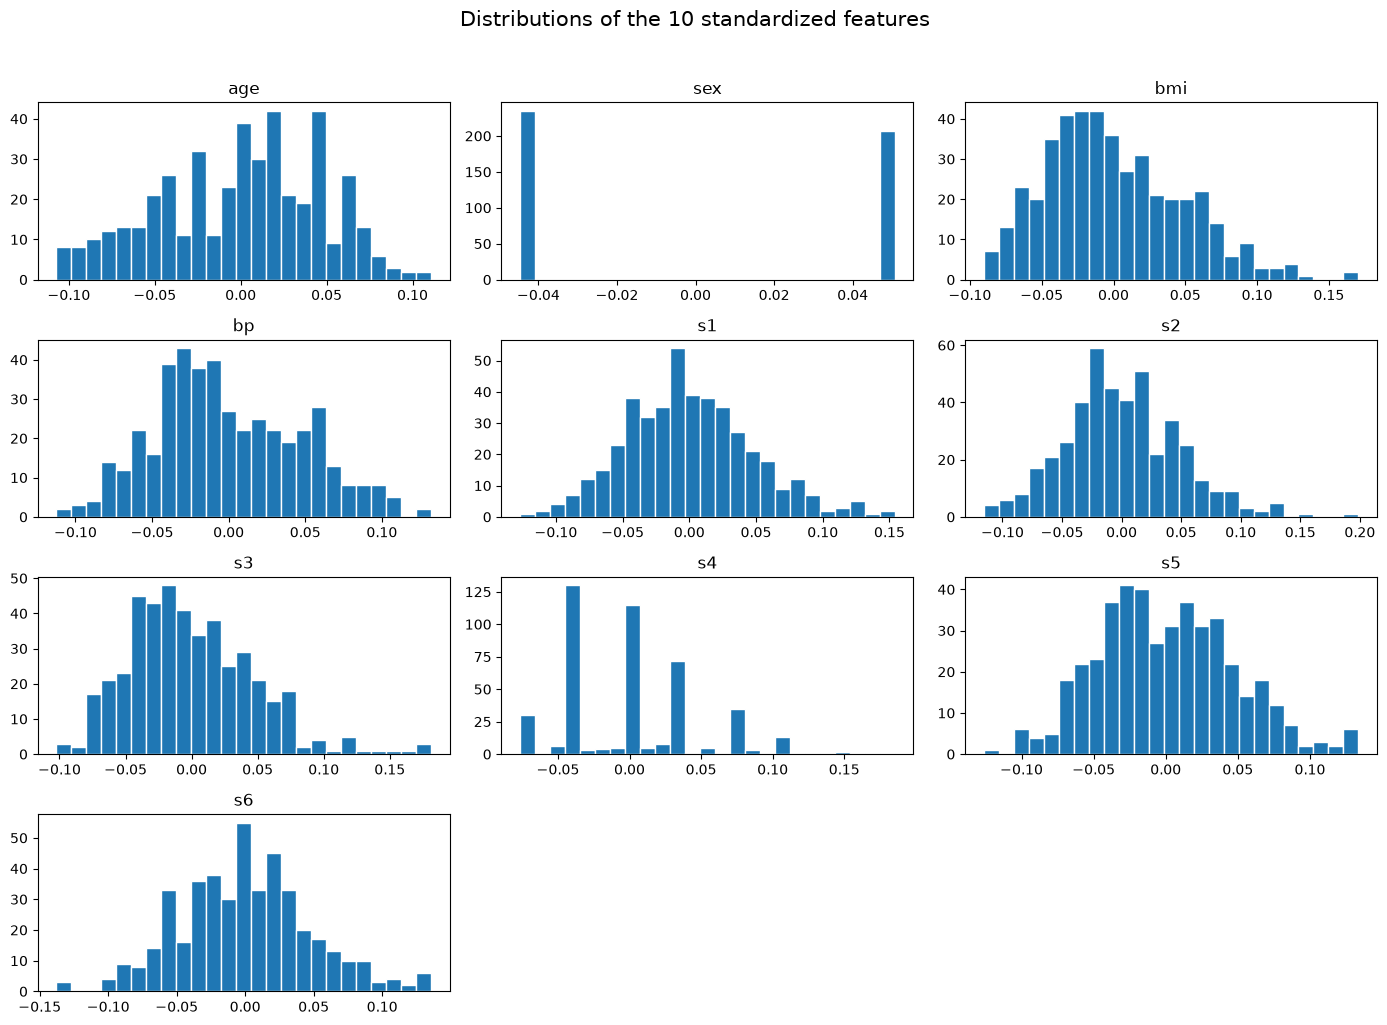

In [7]:
axes = X.hist(figsize=(14, 10), bins=25, edgecolor="white", grid=False)
plt.suptitle("Distributions of the 10 standardized features", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()


## 7. Target distribution

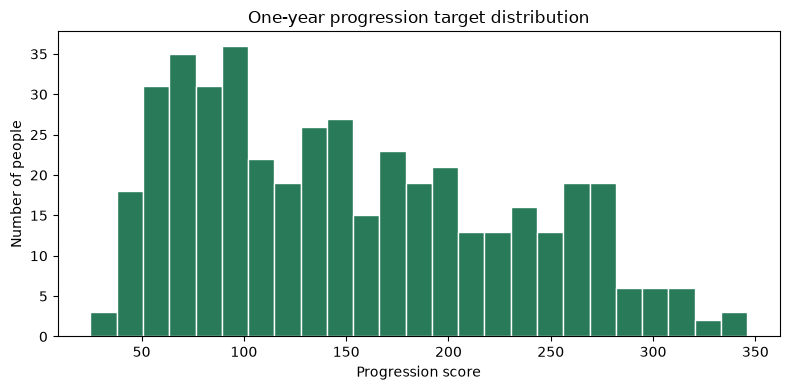

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y, bins=25, color="#287a59", edgecolor="white")
ax.set(title="One-year progression target distribution", xlabel="Progression score", ylabel="Number of people")
plt.tight_layout()
plt.show()


## 8. Box plots and possible outliers

Box plots flag values far from the middle half of this dataset. A flagged value is not automatically an error or a medically abnormal value.

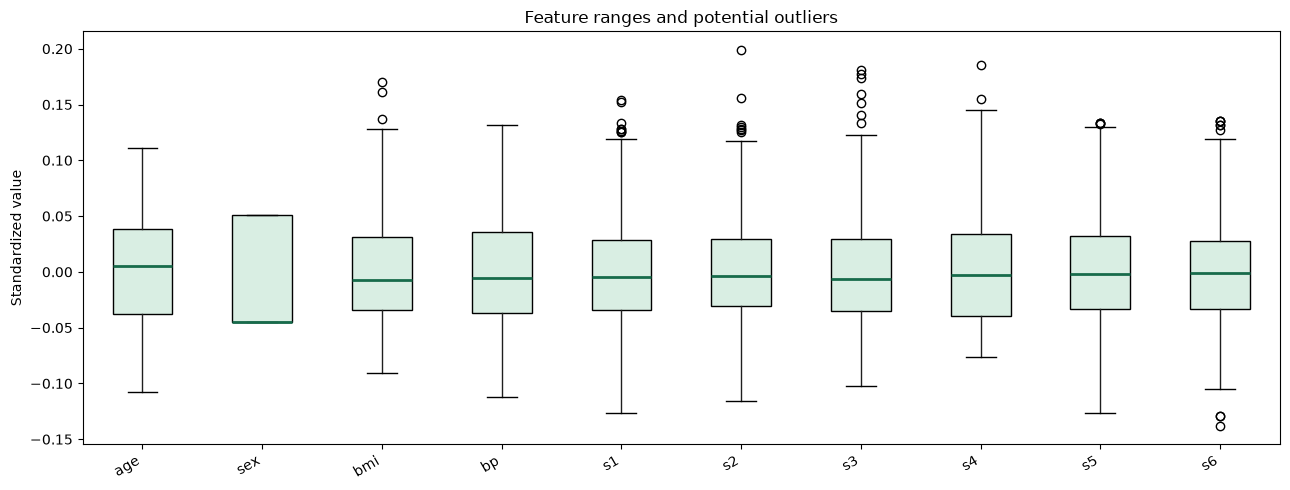

In [9]:
fig, ax = plt.subplots(figsize=(13, 5))
X.boxplot(ax=ax, grid=False, patch_artist=True,
          boxprops={"facecolor": "#d9eee3"}, medianprops={"color": "#176b4b", "linewidth": 2})
ax.set(title="Feature ranges and potential outliers", ylabel="Standardized value")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 9. Skewness

Skewness measures asymmetry: around 0 is roughly symmetric, positive values have a longer right tail, and negative values have a longer left tail. This is a descriptive clue, not a pass/fail test.

,skewness,direction
age,-0.231,roughly symmetric (|skew| < 0.5)
sex,0.127,roughly symmetric (|skew| < 0.5)
s6,0.208,roughly symmetric (|skew| < 0.5)
bp,0.291,roughly symmetric (|skew| < 0.5)
s5,0.292,roughly symmetric (|skew| < 0.5)
s1,0.378,roughly symmetric (|skew| < 0.5)
s2,0.437,roughly symmetric (|skew| < 0.5)
progression,0.441,roughly symmetric (|skew| < 0.5)
bmi,0.598,right-skewed
s4,0.735,right-skewed


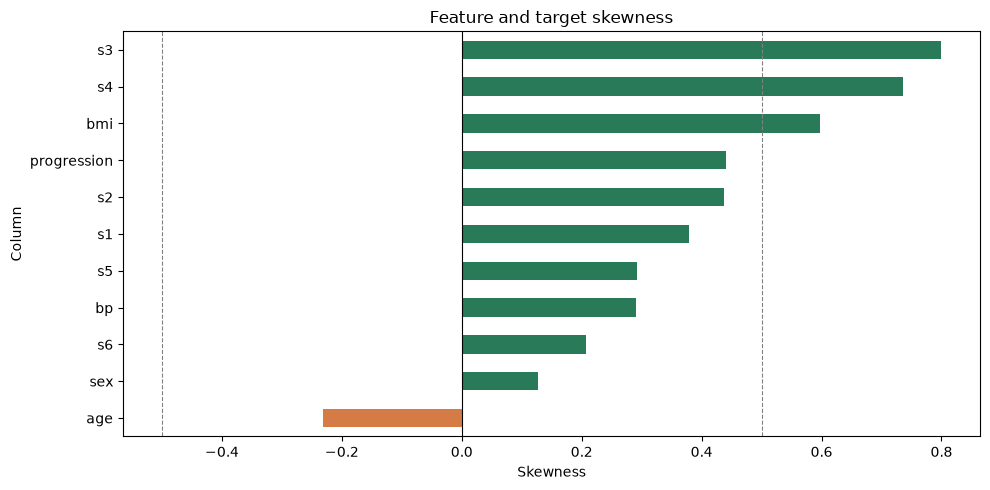

In [10]:
skewness = df.skew().sort_values()
skew_table = pd.DataFrame({"skewness": skewness, "direction": np.where(skewness > 0, "right-skewed", "left-skewed")})
skew_table.loc[skewness.abs() < 0.5, "direction"] = "roughly symmetric (|skew| < 0.5)"
display(skew_table.round(3))

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#287a59" if value >= 0 else "#d57b45" for value in skewness]
skewness.plot(kind="barh", ax=ax, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.axvline(0.5, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(-0.5, color="gray", linestyle="--", linewidth=0.8)
ax.set(title="Feature and target skewness", xlabel="Skewness", ylabel="Column")
plt.tight_layout()
plt.show()


## 10. Correlation heatmap

Correlation ranges from −1 to +1 and describes linear association. Correlation does not show cause and effect.

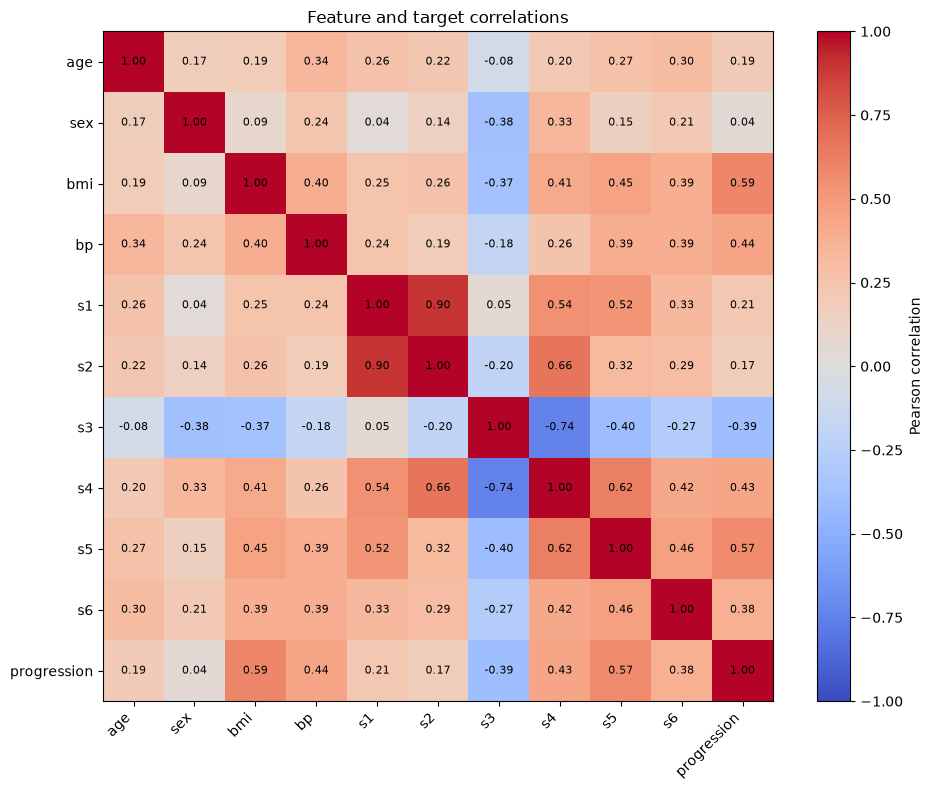

In [11]:
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
for row in range(len(corr.index)):
    for col in range(len(corr.columns)):
        ax.text(col, row, f"{corr.iloc[row, col]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Feature and target correlations")
plt.tight_layout()
plt.show()


## 11. Correlation with the target

This ranks features by their linear correlation with the progression target. It does not measure the full predictive value of a feature.

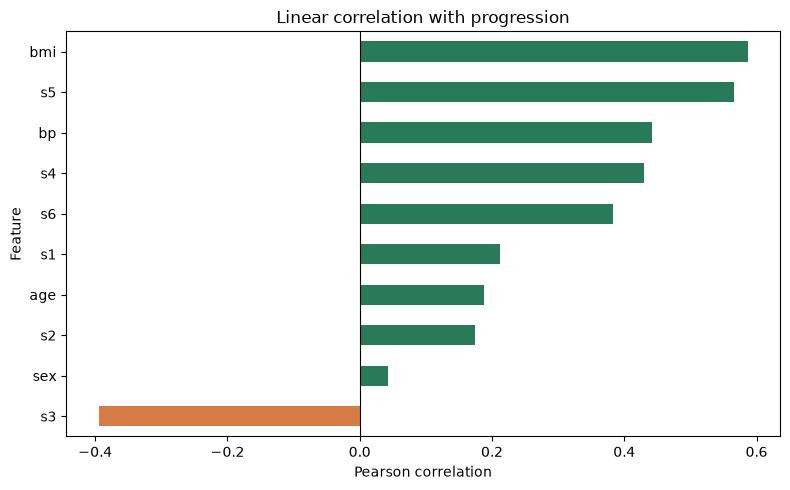

In [12]:
target_corr = corr["progression"].drop("progression").sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
target_corr.plot(kind="barh", ax=ax, color=["#d57b45" if v < 0 else "#287a59" for v in target_corr])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Linear correlation with progression", xlabel="Pearson correlation", ylabel="Feature")
plt.tight_layout()
plt.show()


## 12. Feature versus target scatter plots

Each point is one row. The red line shows a simple linear trend to help see broad patterns; it is not a fitted final model.

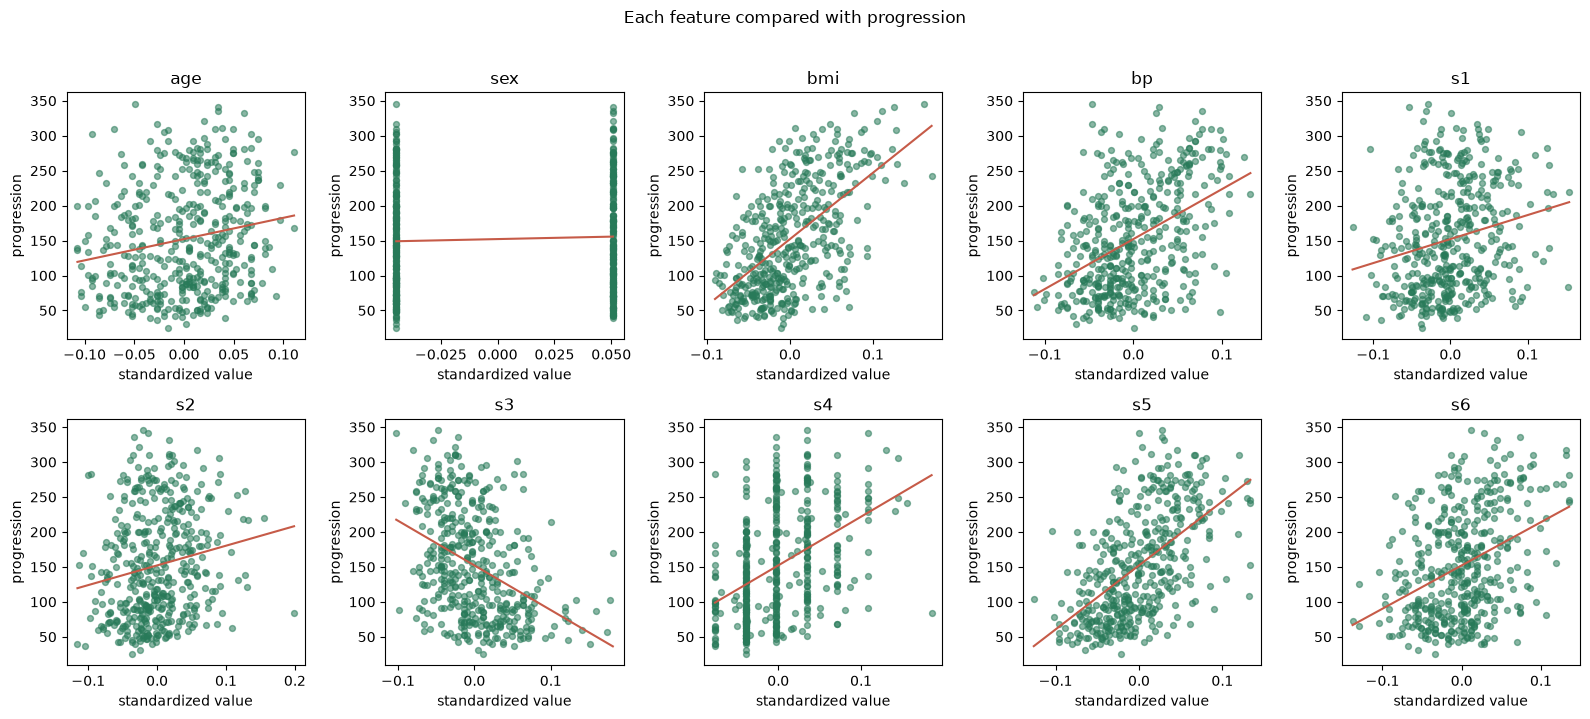

In [13]:
features = list(X.columns)
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for name, ax in zip(features, axes.flat):
    ax.scatter(X[name], y, alpha=0.55, s=18, color="#287a59")
    slope, intercept = np.polyfit(X[name], y, 1)
    line_x = np.linspace(X[name].min(), X[name].max(), 100)
    ax.plot(line_x, slope * line_x + intercept, color="#c65b48", linewidth=1.5)
    ax.set(title=name, xlabel="standardized value", ylabel="progression")
fig.suptitle("Each feature compared with progression", y=1.02)
plt.tight_layout()
plt.show()


## 13. Pair plot for selected features

A compact pair plot can show relationships and distributions together. These four features are selected to keep the chart readable.

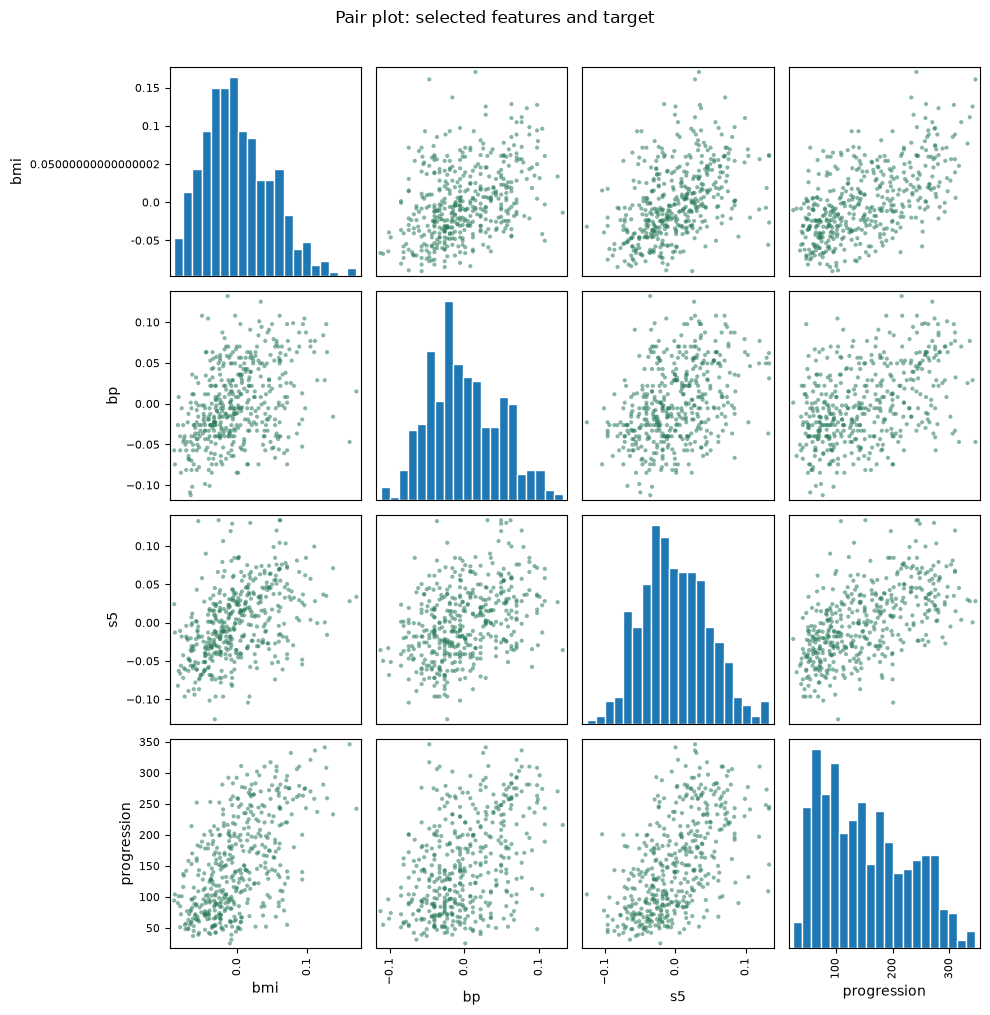

In [14]:
from pandas.plotting import scatter_matrix

selected = ["bmi", "bp", "s5", "progression"]
scatter_matrix(df[selected], figsize=(10, 10), diagonal="hist", alpha=0.55,
              color="#287a59", hist_kwds={"bins": 20, "edgecolor": "white"})
plt.suptitle("Pair plot: selected features and target", y=1.01)
plt.tight_layout()
plt.show()


## 14. Explore any two columns

Change `x_feature` and `y_feature` below to inspect a different pair.

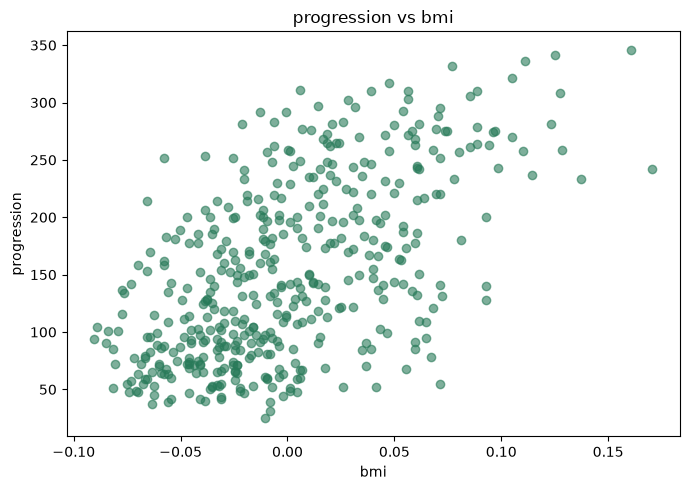

In [15]:
x_feature = "bmi"
y_feature = "progression"

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df[x_feature], df[y_feature], alpha=0.6, color="#287a59")
ax.set(title=f"{y_feature} vs {x_feature}", xlabel=x_feature, ylabel=y_feature)
plt.tight_layout()
plt.show()


In [16]:
%pip install ydata-profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 25.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 26.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 9.2 MB/s  0:00:04 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 27.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 25.4 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 665.5/665.5 kB 17.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.9/20.9 MB 18.6 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 25.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 22.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 22.9 MB/s  0:00:00
  Attempting uninstall: numpym━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2/24 [minify-html]
    Found existing installation: numpy 2.4.6━━━━━━━━━━━━━━━━━━  2/24 [minify-html]
    Uninstalling nu

In [18]:
%pip install --upgrade setuptools

Note: you may need to restart the kernel to use updated packages.


In [19]:
import sys
print(sys.executable)

/Users/rohit/miniconda3/envs/ml/bin/python


In [20]:
from ydata_profiling import ProfileReport

profile = ProfileReport(df, title="Diabetes Dataset EDA", explorative=True)
profile.to_notebook_iframe()

ModuleNotFoundError: No module named 'pkg_resources'

## Takeaways

Use the plots and tables to describe distributions, skew, possible extreme observations, and linear relationships. Remember that feature values are transformed, the sample is small, associations do not establish causation, and the target is a dataset research measure rather than a clinical outcome for use in diagnosis.